# Thành viên 2 – Tiền xử lý dữ liệu Cora & Baseline MLP
- Dataset: Cora (semi-supervised: 140 train / 500 val / 1000 test, 20 nhãn/lớp ở tập train)
- Baseline: MLP 2 lớp, **chỉ dùng đặc trưng node X**, bỏ qua ma trận kề A
- Chọn model theo **Validation accuracy**; test chỉ được đọc tại epoch val tốt nhất
- Báo cáo mean ± std qua nhiều seed

In [1]:
import random
import numpy as np
import torch
import torch.nn as nn
import torch.nn.functional as F
import matplotlib.pyplot as plt
from torch_geometric.datasets import Planetoid
import torch_geometric.transforms as T

def set_seed(seed):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Device:", device)

d:\Hoctap\Đồ án tổng hợp\.venv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm
d:\Hoctap\Đồ án tổng hợp\.venv\Lib\site-packages\torch\jit\_script.py:1491: FutureWarning: `torch.jit.script` is deprecated. Please switch to `torch.compile` or `torch.export`.
  warnings.warn(


Device: cpu


## 1. Tải và chuẩn hóa Cora

In [2]:
# split mặc định của Planetoid là 'public' (chuẩn semi-supervised của Kipf & Welling)
dataset = Planetoid(root='../data/Cora', name='Cora',
                    split='public',
                    transform=T.NormalizeFeatures())   # chuẩn hóa L1 theo hàng cho X
data = dataset[0].to(device)

num_classes = dataset.num_classes
train_per_class = torch.bincount(data.y[data.train_mask], minlength=num_classes).tolist()

print("=== TỔNG QUAN TẬP DỮ LIỆU CORA ===")
print(f"• Số lượng Nodes (Bài báo):        {data.num_nodes}")
print(f"• Số lượng Features/Node:         {dataset.num_node_features}")
print(f"• Số lượng Classes (Phân lớp):     {num_classes}")
print(f"• Số cạnh có hướng (PyG, 2 chiều): {data.num_edges}")
print(f"• Số cạnh vô hướng tương ứng:      {data.num_edges // 2}")
print("-" * 45)
print(f"• Tập Train:      {data.train_mask.sum().item()} nodes | nhãn/lớp: {train_per_class}")
print(f"• Tập Validation: {data.val_mask.sum().item()} nodes")
print(f"• Tập Test:       {data.test_mask.sum().item()} nodes")

Processing...


=== TỔNG QUAN TẬP DỮ LIỆU CORA ===
• Số lượng Nodes (Bài báo):        2708
• Số lượng Features/Node:         1433
• Số lượng Classes (Phân lớp):     7
• Số cạnh có hướng (PyG, 2 chiều): 10556
• Số cạnh vô hướng tương ứng:      5278
---------------------------------------------
• Tập Train:      140 nodes | nhãn/lớp: [20, 20, 20, 20, 20, 20, 20]
• Tập Validation: 500 nodes
• Tập Test:       1000 nodes


Done!


> **Ghi chú số cạnh:** đề bài ghi 5.429 cạnh là số của bản Cora gốc. Sau khi loại cạnh trùng lặp và
> self-loop, PyG còn **5.278 cạnh vô hướng**, được lưu thành **10.556 cạnh có hướng** (mỗi cạnh 2 chiều).
> Đây không phải lỗi tải dữ liệu.

## 2. Mô hình MLP baseline (không dùng ma trận kề)

In [3]:
class MLP(nn.Module):
    def __init__(self, in_channels, hidden_channels, out_channels,
                 dropout=0.5, input_dropout=True):
        super().__init__()
        self.fc1 = nn.Linear(in_channels, hidden_channels)
        self.fc2 = nn.Linear(hidden_channels, out_channels)
        self.dropout = dropout
        self.input_dropout = input_dropout   # GCN gốc (Kipf & Welling) có dropout cả ở input

    def forward(self, x):                    # KHÔNG nhận edge_index
        if self.input_dropout:
            x = F.dropout(x, p=self.dropout, training=self.training)
        x = F.relu(self.fc1(x))
        x = F.dropout(x, p=self.dropout, training=self.training)
        x = self.fc2(x)
        return F.log_softmax(x, dim=1)

## 3. Huấn luyện và đánh giá

In [4]:
# Siêu tham số (giữ giống GCN của các thành viên khác để so sánh công bằng)
HIDDEN, DROPOUT, LR, WEIGHT_DECAY, EPOCHS = 16, 0.5, 0.01, 5e-4, 200

@torch.no_grad()
def accuracy(model, mask):
    model.eval()
    pred = model(data.x).argmax(dim=1)
    return (pred[mask] == data.y[mask]).float().mean().item()

def run(seed, verbose=False):
    set_seed(seed)
    model = MLP(dataset.num_node_features, HIDDEN, num_classes, DROPOUT).to(device)
    optimizer = torch.optim.Adam(model.parameters(), lr=LR, weight_decay=WEIGHT_DECAY)

    hist = {"train_loss": [], "val_acc": [], "test_acc": []}
    best_val_acc, test_at_best_val, best_epoch = 0.0, 0.0, 0

    for epoch in range(1, EPOCHS + 1):
        # Train: chỉ dùng data.x, hoàn toàn bỏ qua data.edge_index
        model.train()
        optimizer.zero_grad()
        out = model(data.x)
        loss = F.nll_loss(out[data.train_mask], data.y[data.train_mask])
        loss.backward()
        optimizer.step()

        # Evaluate
        val_acc = accuracy(model, data.val_mask)
        test_acc = accuracy(model, data.test_mask)
        hist["train_loss"].append(loss.item())
        hist["val_acc"].append(val_acc)
        hist["test_acc"].append(test_acc)

        # Chọn theo Validation: chỉ ghi lại test tại epoch có val tốt nhất
        if val_acc > best_val_acc:
            best_val_acc, test_at_best_val, best_epoch = val_acc, test_acc, epoch

        if verbose and (epoch == 1 or epoch % 20 == 0):
            print(f"Epoch {epoch:03d} | Train Loss: {loss.item():.4f} | "
                  f"Val Acc: {val_acc:.4f} | Test Acc: {test_acc:.4f}")

    return best_val_acc, test_at_best_val, best_epoch, hist

# Chạy chi tiết 1 seed để xem quá trình huấn luyện
print("BẮT ĐẦU HUẤN LUYỆN BASELINE MLP (seed 0)...")
v, t, e, hist0 = run(seed=0, verbose=True)
print(f"\nSeed 0 -> Val Acc tốt nhất: {v*100:.2f}% (epoch {e}) | Test Acc tại epoch đó: {t*100:.2f}%")

BẮT ĐẦU HUẤN LUYỆN BASELINE MLP (seed 0)...
Epoch 001 | Train Loss: 1.9592 | Val Acc: 0.1220 | Test Acc: 0.1300
Epoch 020 | Train Loss: 1.8449 | Val Acc: 0.1900 | Test Acc: 0.1840
Epoch 040 | Train Loss: 1.5847 | Val Acc: 0.4120 | Test Acc: 0.4240
Epoch 060 | Train Loss: 1.2289 | Val Acc: 0.4800 | Test Acc: 0.4900
Epoch 080 | Train Loss: 1.0018 | Val Acc: 0.5340 | Test Acc: 0.5350
Epoch 100 | Train Loss: 0.9293 | Val Acc: 0.5640 | Test Acc: 0.5580
Epoch 120 | Train Loss: 0.8567 | Val Acc: 0.5640 | Test Acc: 0.5590
Epoch 140 | Train Loss: 0.7389 | Val Acc: 0.5700 | Test Acc: 0.5680
Epoch 160 | Train Loss: 0.7049 | Val Acc: 0.5700 | Test Acc: 0.5660
Epoch 180 | Train Loss: 0.6042 | Val Acc: 0.5620 | Test Acc: 0.5620
Epoch 200 | Train Loss: 0.6367 | Val Acc: 0.5500 | Test Acc: 0.5500

Seed 0 -> Val Acc tốt nhất: 59.00% (epoch 193) | Test Acc tại epoch đó: 56.80%


## 4. Kết quả qua nhiều seed (mean ± std)

In [5]:
SEEDS = list(range(10))
results = [run(s) for s in SEEDS]
val_accs  = np.array([r[0] for r in results]) * 100
test_accs = np.array([r[1] for r in results]) * 100

for s, v, t in zip(SEEDS, val_accs, test_accs):
    print(f"Seed {s}: Val {v:.2f}% | Test (tại epoch Val tốt nhất) {t:.2f}%")

print("\n" + "=" * 60)
print(f"MLP Baseline ({len(SEEDS)} seeds)")
print(f"  Val  Acc: {val_accs.mean():.2f} ± {val_accs.std():.2f} %")
print(f"  Test Acc (tại epoch Validation tốt nhất): {test_accs.mean():.2f} ± {test_accs.std():.2f} %")
print("=" * 60)

Seed 0: Val 59.00% | Test (tại epoch Val tốt nhất) 56.80%
Seed 1: Val 60.80% | Test (tại epoch Val tốt nhất) 58.10%
Seed 2: Val 58.80% | Test (tại epoch Val tốt nhất) 58.50%
Seed 3: Val 61.40% | Test (tại epoch Val tốt nhất) 58.00%
Seed 4: Val 60.60% | Test (tại epoch Val tốt nhất) 58.30%
Seed 5: Val 59.60% | Test (tại epoch Val tốt nhất) 57.90%
Seed 6: Val 61.40% | Test (tại epoch Val tốt nhất) 59.60%
Seed 7: Val 59.80% | Test (tại epoch Val tốt nhất) 57.60%
Seed 8: Val 60.80% | Test (tại epoch Val tốt nhất) 59.30%
Seed 9: Val 61.40% | Test (tại epoch Val tốt nhất) 57.90%

MLP Baseline (10 seeds)
  Val  Acc: 60.36 ± 0.94 %
  Test Acc (tại epoch Validation tốt nhất): 58.20 ± 0.76 %


## 5. Learning curves (seed 0)

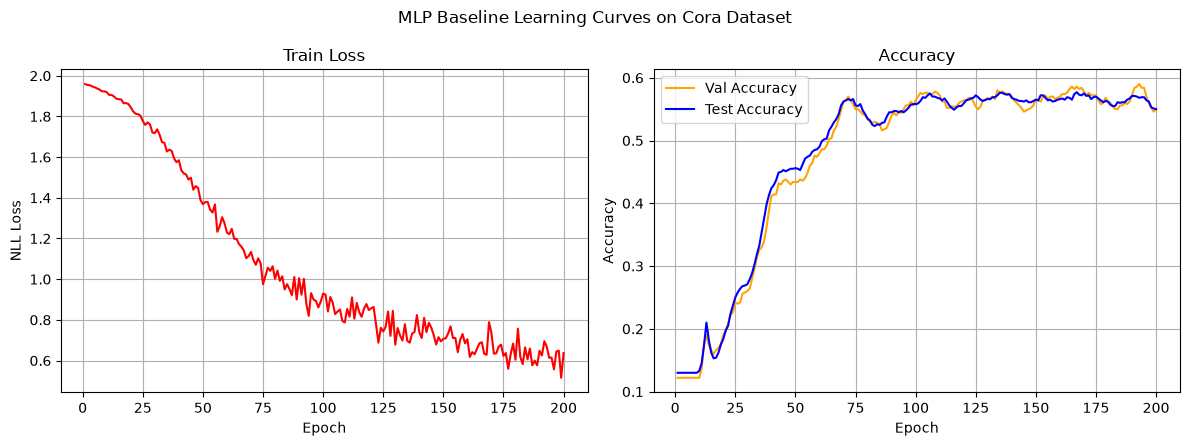

In [6]:
epochs = range(1, EPOCHS + 1)
fig, ax = plt.subplots(1, 2, figsize=(12, 4.5))

ax[0].plot(epochs, hist0["train_loss"], color='red')
ax[0].set_title('Train Loss')
ax[0].set_xlabel('Epoch'); ax[0].set_ylabel('NLL Loss'); ax[0].grid(True)

ax[1].plot(epochs, hist0["val_acc"], label='Val Accuracy', color='orange')
ax[1].plot(epochs, hist0["test_acc"], label='Test Accuracy', color='blue')
ax[1].set_title('Accuracy')
ax[1].set_xlabel('Epoch'); ax[1].set_ylabel('Accuracy'); ax[1].legend(); ax[1].grid(True)

fig.suptitle('MLP Baseline Learning Curves on Cora Dataset')
plt.tight_layout()
plt.show()

## 6. Kiểm tra tính chính xác của dữ liệu

In [7]:
print("=== KIỂM TRA TÍNH CHÍNH XÁC CỦA DỮ LIỆU CORA ===")
ok = lambda c: '✅ ĐÚNG' if c else '❌ SAI'

print(f"1. Nodes (2,708):                  {ok(data.num_nodes == 2708)}")
print(f"2. Features (1,433):               {ok(data.x.shape[1] == 1433)}")
print(f"3. Classes (7):                    {ok(len(torch.unique(data.y)) == 7)}")
print(f"4. Cạnh có hướng (10,556 = 2x5,278): {ok(data.num_edges == 10556)}")

n_tr, n_va, n_te = (data.train_mask.sum().item(), data.val_mask.sum().item(),
                    data.test_mask.sum().item())
print(f"5. Split 140/500/1000:             {ok((n_tr, n_va, n_te) == (140, 500, 1000))}")

counts = torch.bincount(data.y[data.train_mask], minlength=7).tolist()
print(f"6. Train 20 mẫu/lớp:               {ok(counts == [20]*7)} {counts}")

overlap = ((data.train_mask & data.val_mask).any() or
           (data.train_mask & data.test_mask).any() or
           (data.val_mask & data.test_mask).any())
print(f"7. Các tập không trùng lấp:        {ok(not overlap)}")

row_sums = data.x.sum(dim=1)
print(f"8. Chuẩn hóa L1 theo hàng (X):     {ok(torch.allclose(row_sums, torch.ones_like(row_sums), atol=1e-3))}")

has_nan = torch.isnan(data.x).any() or torch.isnan(data.y.float()).any()
print(f"9. Không có NaN:                   {ok(not has_nan)}")

import inspect
uses_edges = 'edge_index' in inspect.signature(MLP.forward).parameters
print(f"10. MLP không dùng ma trận kề A:   {ok(not uses_edges)}")

=== KIỂM TRA TÍNH CHÍNH XÁC CỦA DỮ LIỆU CORA ===
1. Nodes (2,708):                  ✅ ĐÚNG
2. Features (1,433):               ✅ ĐÚNG
3. Classes (7):                    ✅ ĐÚNG
4. Cạnh có hướng (10,556 = 2x5,278): ✅ ĐÚNG
5. Split 140/500/1000:             ✅ ĐÚNG
6. Train 20 mẫu/lớp:               ✅ ĐÚNG [20, 20, 20, 20, 20, 20, 20]
7. Các tập không trùng lấp:        ✅ ĐÚNG
8. Chuẩn hóa L1 theo hàng (X):     ✅ ĐÚNG
9. Không có NaN:                   ✅ ĐÚNG
10. MLP không dùng ma trận kề A:   ✅ ĐÚNG
